# 1 -Introduction

# 2 Pre-requisites

## 1-1-Library Importing :
**we will use Nibabel for handling NIFTI : stands for "NeuroImaging Informatics Technology Initiative"**

In [27]:
from google.colab import drive , userdata

## Utilities
import os ,  random
from collections import defaultdict
from tqdm import  tqdm
import zipfile
from typing import List , Tuple


#Data processing & Visualisation

import numpy as np

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
from ipywidgets import interact , IntSlider

## Medical Imaging & U-Net Implementation
import nibabel as nib
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset , DataLoader
from sklearn.model_selection import train_test_split


## 1-2:Data setUp: Google Drive


In [28]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [29]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [30]:
project_path = "/content/drive/MyDrive/BratsData"

In [31]:
dataset_path = os.path.join(project_path, "MICCAI_BraTS_2019_Data_Training")

## 1-3:BraTs 2019 DownLoad

**that is tha Dataset Download link**:https://www.kaggle.com/datasets/aryashah2k/brain-tumor-segmentation-brats-2019

**Since the BraTS 2019 dataset is no longer available through its official website (https://www.med.upenn.edu/cbica/brats2019/data.html), we will download it from Kaggle instead.**

In [32]:
# Install the latest Kaggle tool (as required by the new tokens)
!pip install -U kaggle

In [33]:
from google.colab import userdata
try:
    username = userdata.get('KAGGLE_USERNAME')
    print("Successfully retrieved KAGGLE_USERNAME!")
except Exception as e:
    print(f"Error: {e}")
    print("Please add 'KAGGLE_USERNAME' and 'KAGGLE_KEY' to your Colab Secrets (the key icon on the left sidebar) and grant access.")

Successfully retrieved KAGGLE_USERNAME!


In [34]:
# Link Colab Secrets to the environment
os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')

In [35]:
# Download and Unzip BraTS 2019
!kaggle datasets download --d aryashah2k/brain-tumor-segmentation-brats-2019

Dataset URL: https://www.kaggle.com/datasets/aryashah2k/brain-tumor-segmentation-brats-2019
License(s): CC0-1.0
brain-tumor-segmentation-brats-2019.zip: Skipping, found more recently modified local copy (use --force to force download)


##### Note that our dataset has been downloaded to the following path:
**/content/brain-tumor-segmentation-brats-2019.zip**

this is a temporary storage and this file will be wiped out if we restart this Colab session.

Therefore, we should unzip the dataset inside our Google Drive to permanently save it. Let’s unzip the file to the following destination folder:

**/content/drive/MyDrive/BratsData**


In [36]:
source_file = "/content/brain-tumor-segmentation-brats-2019.zip"
destination_folder = project_path

In [37]:
if os.path.exists(dataset_path):
    print(f"Dataset folder '{dataset_path}' already exists. Skipping unzipping.")
else:
  if not os.path.exists(destination_folder):
    os.makedirs(destination_folder)
    print(f"Unzipping {source_file} to {destination_folder}...")
    with zipfile.ZipFile(source_file, 'r') as zip_ref:
        zip_ref.extractall(destination_folder)
    print("Done! Your files have been unzipped to your Google Drive.")

Unzipping /content/brain-tumor-segmentation-brats-2019.zip to /content/drive/MyDrive/BratsData...
Done! Your files have been unzipped to your Google Drive.


Now that we have unzipped our data , we need to make sur everything arrived correctly **Let's confirm that we have all the 259 High-Grade (HDD) and 76 Low-Grad(LGG) Patients

In [38]:
def verify_counts(base_path:str , expected_hgg :int , expected_lgg:int) ->int :
  print(f"Ckecking folders in :{base_path}\n")

  hgg_path=os.path.join(base_path , "HGG")
  if os.path.exists(hgg_path) :
    hgg_count = len([f for f in os.listdir(hgg_path) if os.path.isdir(os.path.join(hgg_path , f))])
    status = "MATCH" if hgg_count == expected_hgg else "MISMATCH"
    print(f"HGG Folders: {hgg_count} (Expected: {expected_hgg}) -> {status}")

  else :
    print(f"this folder not found!! ")

  lgg_path= os.path.join(base_path , "LGG")
  if os.path.exists(lgg_path) :
    lgg_count = len([f for f in os.listdir(lgg_path) if os.path.isdir(os.path.join(lgg_path , f))])
    status = " MATCH" if lgg_count == expected_lgg else " MISMATCH"
    print(f"LGG Folders: {lgg_count} (Expected: {expected_lgg}) -> {status}")

  else :
    print("Error: LGG folder not found!")

  total = hgg_count + lgg_count
  print(f"\nTotal Patients: {total}")


In [39]:
verify_counts(dataset_path  , expected_hgg=259 , expected_lgg=76)

Ckecking folders in :/content/drive/MyDrive/BratsData/MICCAI_BraTS_2019_Data_Training

HGG Folders: 259 (Expected: 259) -> MATCH
LGG Folders: 76 (Expected: 76) ->  MATCH

Total Patients: 335


## 1-4 :Device Selection

**select GPU if is available**

In [40]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device :" , device)

Using device : cuda


#2 :Hands-On code Implemetation


## 2-1: Fixed Random Seed for Reproducibility

In [41]:
def set_seed(seed:int = 42) -> None:
    """
    Sets global seeds for reproducibility across Python, NumPy, and PyTorch.
    """
    # 1. Base Python and NumPy seeds
    random.seed(seed)
    np.random.seed(seed)

    # 2. PyTorch CPU and GPU seeds
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # 3. CuDNN backend settings (The "Pro" settings for GPU consistency)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    print(f"✅ Reproducibility locked! Seed set to: {seed}")

In [42]:
set_seed(42)

✅ Reproducibility locked! Seed set to: 42


## 2-2 :Exploratory Data Analysis (EDA)

#### BraTS 2019 Dataset Structure

The BraTS 2019 training dataset is organized into two main categories:

- **HGG:** High-Grade Gliomas
- **LGG:** Low-Grade Gliomas

Each patient has a separate folder containing four MRI modalities and one segmentation mask.

```text
MICCAI_BraTS_2019_Data_Training/
├── HGG/ (High-Grade Gliomas)
│   ├── BraTS19_2013_10_1/
│   │   ├── BraTS19_2013_10_1_flair.nii  # Fluid Attenuated Inversion Recovery
│   │   ├── BraTS19_2013_10_1_t1.nii     # T1-weighted
│   │   ├── BraTS19_2013_10_1_t1ce.nii   # T1-weighted Contrast Enhanced
│   │   ├── BraTS19_2013_10_1_t2.nii     # T2-weighted
│   │   └── BraTS19_2013_10_1_seg.nii    # Ground Truth Segmentation Mask
│   └── ... (Other HGG patient folders)
│
└── LGG/ (Low-Grade Gliomas)
    ├── BraTS19_2013_0_1/
    │   ├── BraTS19_2013_0_1_flair.nii
    │   ├── BraTS19_2013_0_1_t1.nii
    │   ├── BraTS19_2013_0_1_t1ce.nii
    │   ├── BraTS19_2013_0_1_t2.nii
    │   └── BraTS19_2013_0_1_seg.nii
    └── ... (Other LGG patient folders)

### Dataset Statistics

In [43]:
modalities = ["t1", "t1ce", "t2", "flair"]
seg_keyword = "seg"

## Tumor classes
tumor_class = ["HGG" , "LGG"]

In [44]:
def count_dataset_statistics(dataset_path):
    stats = {}

    for tumor_class in ["HGG", "LGG"]:
        class_dir = os.path.join(dataset_path, tumor_class)
        patient_folders = [
            d for d in os.listdir(class_dir)
            if os.path.isdir(os.path.join(class_dir, d))
        ]

        stats[tumor_class] = {
            "num_patients": len(patient_folders),
            "modalities": defaultdict(int),
            "segmentation_masks": 0
        }

        for patient in patient_folders:
            patient_dir = os.path.join(class_dir, patient)
            files = os.listdir(patient_dir)

            for f in files:
                fname = f.lower()

                # Count segmentation mask
                if fname.endswith("_seg.nii") or fname.endswith("_seg.nii.gz"):
                    stats[tumor_class]["segmentation_masks"] += 1

                # Count modalities (exact match)
                for mod in modalities:
                    if fname.endswith(f"_{mod}.nii") or fname.endswith(f"_{mod}.nii.gz"):
                        stats[tumor_class]["modalities"][mod] += 1

    return stats

In [45]:
stats = count_dataset_statistics(dataset_path)

In [46]:
# ---- Run to display statistics ----
for tumor_class, info in stats.items():
    print(f"\nClass: {tumor_class}")
    print(f"  Number of patients: {info['num_patients']}")
    print("  Number of files per modality:")
    for mod in modalities:
        print(f"    {mod.upper():6s}: {info['modalities'][mod]}")
    print(f"  Segmentation masks: {info['segmentation_masks']}")


Class: HGG
  Number of patients: 259
  Number of files per modality:
    T1    : 259
    T1CE  : 259
    T2    : 259
    FLAIR : 259
  Segmentation masks: 259

Class: LGG
  Number of patients: 76
  Number of files per modality:
    T1    : 76
    T1CE  : 76
    T2    : 76
    FLAIR : 76
  Segmentation masks: 76


**In the next few cells, we will randomly select one patient from each category and visualize three different “slices” of their brain. Since a brain scan is 3D, we take slices at the 25%,50%, and 75% marks to get a full view of the tumor’s location.**

In [47]:
def random_patient(base_dir :str , grade : str = "HGG") :
  grade_dir = os.path.join(base_dir , grade)
  patients = sorted(os.listdir(grade_dir))
  patient = random.choice(patients)

  return os.path.join(grade_dir , patient) , patient

In [48]:
def load_brats_case(patient_dir, modality="flair"):
    files = os.listdir(patient_dir)

    #img_file = [f for f in files if modality in f.lower()][0]
    img_file = [f for f in files if f.lower().endswith(f"_{modality.lower()}.nii")][0]
    seg_file = [f for f in files if "seg" in f.lower()][0]

    img = nib.load(os.path.join(patient_dir, img_file)).get_fdata()
    seg = nib.load(os.path.join(patient_dir, seg_file)).get_fdata()

    return img, seg

In [49]:
def normalize_to_uint8(volume):
    """
    Normalize a 3D volume to uint8 [0, 255] for visualization only.
    """
    v = volume.copy()
    v = (v - v.min()) / (v.max() - v.min() + 1e-8)
    v = (v * 255).astype(np.uint8)
    return v

**we will randomly select one patient in each category**

In [50]:
hgg_patient_path, hgg_patient_id = random_patient(dataset_path, "HGG")
lgg_patient_path, lgg_patient_id = random_patient(dataset_path, "LGG")

print(f"Selected HGG patient: {hgg_patient_id} the path to that patient file : {hgg_patient_path}")
print(f"Selected LGG patient: {lgg_patient_id}the path to that patient file : {lgg_patient_path}")

Selected HGG patient: BraTS19_CBICA_AQP_1 the path to that patient file : /content/drive/MyDrive/BratsData/MICCAI_BraTS_2019_Data_Training/HGG/BraTS19_CBICA_AQP_1
Selected LGG patient: BraTS19_2013_1_1the path to that patient file : /content/drive/MyDrive/BratsData/MICCAI_BraTS_2019_Data_Training/LGG/BraTS19_2013_1_1


In [51]:
modality="t2"

hgg_img ,  hgg_seg = load_brats_case(hgg_patient_path )
lgg_img ,  lgg_seg = load_brats_case(lgg_patient_path )

print(f"HGG Image Shape: {hgg_img.shape}" ,
      f"HGG Segmentation Shape: {hgg_seg.shape}")
print(f"LGG Image Shape: {lgg_img.shape}" ,
      f"LGG Segmentation Shape: {lgg_seg.shape}")

HGG Image Shape: (240, 240, 155) HGG Segmentation Shape: (240, 240, 155)
LGG Image Shape: (240, 240, 155) LGG Segmentation Shape: (240, 240, 155)


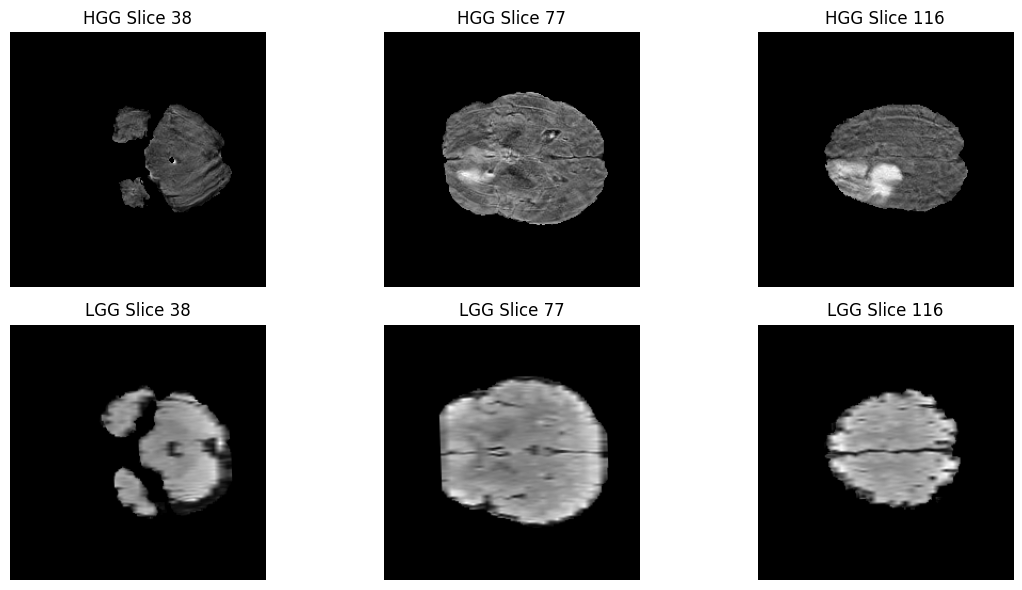

In [52]:
 # Normalize for visualization
hgg_img_vis = normalize_to_uint8(hgg_img)
lgg_img_vis = normalize_to_uint8(lgg_img)

# Select 3 representative slices (25%, 50%, and 75%)
slice_indices = [
    hgg_img.shape[2] // 4,
    hgg_img.shape[2] // 2,
    3 * hgg_img.shape[2] // 4
]

fig, axes = plt.subplots(2, 3, figsize=(12, 6))

for i, z in enumerate(slice_indices):
    axes[0, i].imshow(hgg_img_vis[:, :, z], cmap="gray")
    axes[0, i].set_title(f"HGG Slice {z}")
    axes[0, i].axis("off")

    axes[1, i].imshow(lgg_img_vis[:, :, z], cmap="gray")
    axes[1, i].set_title(f"LGG Slice {z}")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

#### Understanding the Segmentation Masks

A segmentation mask is a 3D volume where each voxel has a label that tells us which region of the brain it belongs to.

The researchers manually labeled the tumor regions to create the ground truth. These labels are used to train our U-Net model.

The mask contains four possible labels:

- **0 – Background:** Normal brain tissue or areas outside the brain.
- **1 – Necrotic / Non-enhancing Core:** The dead or non-enhancing part of the tumor.
- **2 – Edema:** Swelling around the tumor.
- **4 – Enhancing Tumor:** The part of the tumor that appears brighter after contrast injection.

We can think of these labels as a legend on a map. Each number represents a different region of the brain.

We can use `np.unique()` to find all the labels present in the mask.

In [53]:
print(f"HGG segmentation mask shape: {hgg_seg.shape}")
print(f"LGG segmentation mask shape: {lgg_seg.shape}")

hgg_labels = np.unique(hgg_seg)
lgg_labels = np.unique(lgg_seg)

print(f"HGG unique labels: {hgg_labels}")
print(f"LGG unique labels: {lgg_labels}")

print("0 - Background (no tumor)")
print("1 - Necrotic / non-enhancing tumor core")
print("2 - Peritumoral edema")
print("4 - Enhancing tumor")

HGG segmentation mask shape: (240, 240, 155)
LGG segmentation mask shape: (240, 240, 155)
HGG unique labels: [0. 1. 2. 4.]
LGG unique labels: [0. 1. 2.]
0 - Background (no tumor)
1 - Necrotic / non-enhancing tumor core
2 - Peritumoral edema
4 - Enhancing tumor


#### Visualizing the Ground Truth: The Overlay
**we don’t just want to see the MRI; we want to see if the “labels” align perfectly with the structures we see in the scan. By layering the colorful segmentation mask on top of the grayscale MRI, we can see exactly where the tumor core ends and the edema (swelling) begins.**

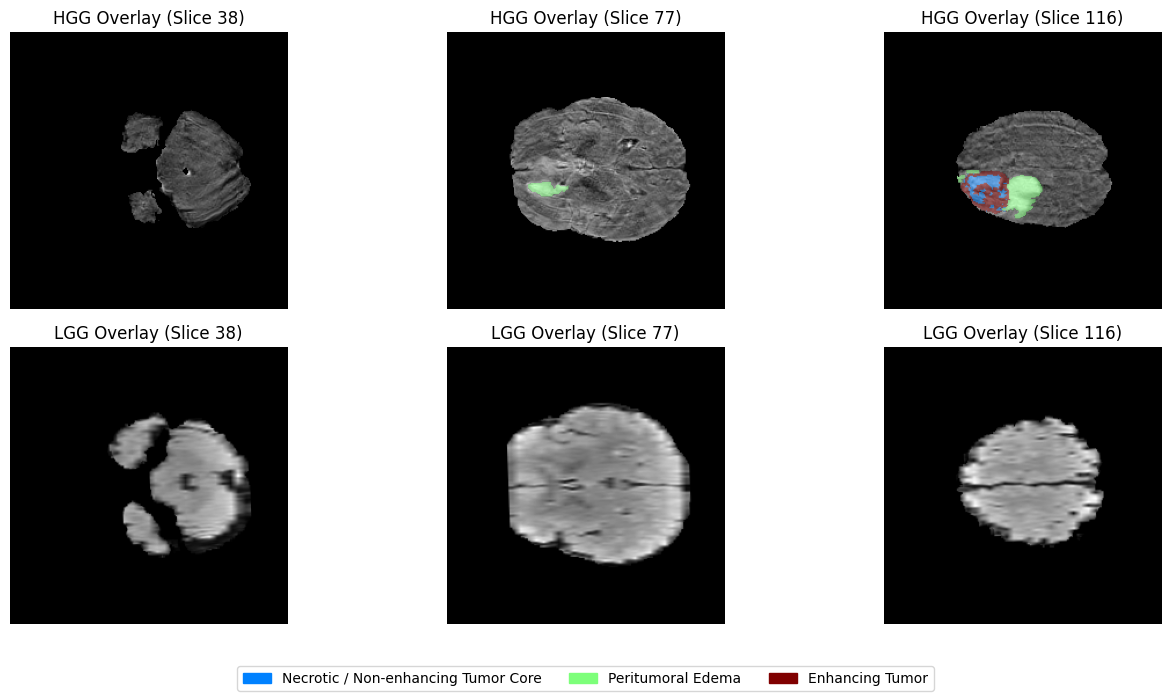

In [54]:
# Define label-to-color mapping (for legend)
label_info = {
    1: "Necrotic / Non-enhancing Tumor Core",
    2: "Peritumoral Edema",
    4: "Enhancing Tumor"
}

# Create legend patches (colors correspond to 'jet' colormap)
legend_patches = [
    mpatches.Patch(color=plt.cm.jet(1/4), label=label_info[1]),
    mpatches.Patch(color=plt.cm.jet(2/4), label=label_info[2]),
    mpatches.Patch(color=plt.cm.jet(4/4), label=label_info[4]),
]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for i, z in enumerate(slice_indices):
    # --- HGG ---
    axes[0, i].imshow(hgg_img_vis[:, :, z], cmap="gray")

    # Create a masked version of the HGG segmentation (hide 0s)
    hgg_mask_data = hgg_seg[:, :, z]
    hgg_masked = np.ma.masked_where(hgg_mask_data == 0, hgg_mask_data)

    # Plot the mask only where it is NOT 0
    axes[0, i].imshow(hgg_masked, cmap="jet", alpha=0.5, vmin=0, vmax=4)
    axes[0, i].set_title(f"HGG Overlay (Slice {z})")
    axes[0, i].axis("off")

    # --- LGG ---
    axes[1, i].imshow(lgg_img_vis[:, :, z], cmap="gray")

    # Create a masked version of the LGG segmentation (hide 0s)
    lgg_mask_data = lgg_seg[:, :, z]
    lgg_masked = np.ma.masked_where(lgg_mask_data == 0, lgg_mask_data)

    # Plot the mask only where it is NOT 0
    axes[1, i].imshow(lgg_masked, cmap="jet", alpha=0.5, vmin=0, vmax=4)
    axes[1, i].set_title(f"LGG Overlay (Slice {z})")
    axes[1, i].axis("off")

# Add legend once for the entire figure
fig.legend(handles=legend_patches, loc="lower center", ncol=3, fontsize=10)
plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()

### Interactive Exploration

In [55]:
def show_slices(volume, seg, title=""):
    """
    Slider-based visualization of axial slices with normalized intensity
    and a clean, masked segmentation overlay.
    """
    volume_vis = normalize_to_uint8(volume)
    max_slice = volume_vis.shape[2] - 1

    # BraTS label definitions
    label_info = {
        1: "Necrotic / Non-enhancing Tumor Core",
        2: "Peritumoral Edema",
        4: "Enhancing Tumor"
    }

    # Create legend patches
    legend_patches = [
        mpatches.Patch(color=plt.cm.jet(1/4), label=label_info[1]),
        mpatches.Patch(color=plt.cm.jet(2/4), label=label_info[2]),
        mpatches.Patch(color=plt.cm.jet(4/4), label=label_info[4]),
    ]

    def view_slice(z):
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))

        # 1. Original grayscale image
        axes[0].imshow(volume_vis[:, :, z], cmap="gray")
        axes[0].set_title(f"{title} - Image (slice {z})")
        axes[0].axis("off")

        # 2. Clean Overlay
        axes[1].imshow(volume_vis[:, :, z], cmap="gray")

        # --- The Fix: Masking the background (0s) ---
        slice_seg = seg[:, :, z]
        masked_seg = np.ma.masked_where(slice_seg == 0, slice_seg)

        # Plot the mask with vmin/vmax to keep colors consistent
        axes[1].imshow(masked_seg, cmap="jet", alpha=0.5, vmin=0, vmax=4)
        axes[1].set_title("Segmentation Overlay")
        axes[1].axis("off")

        # Add legend
        fig.legend(
            handles=legend_patches,
            loc="lower center",
            ncol=3,
            fontsize=10
        )

        plt.tight_layout(rect=[0, 0.15, 1, 1])
        plt.show()

    interact(
        view_slice,
        z=IntSlider(min=0, max=max_slice, step=1, value=max_slice // 2)
    )

In [56]:
print(f"Interactive visualization for HGG patient: {hgg_patient_id}")
show_slices(hgg_img, hgg_seg, title=f"HGG ({hgg_patient_id})")

Interactive visualization for HGG patient: BraTS19_CBICA_AQP_1


interactive(children=(IntSlider(value=77, description='z', max=154), Output()), _dom_classes=('widget-interact…

In [57]:
print(f"Interactive visualization for LGG patient: {lgg_patient_id}")
show_slices(lgg_img, lgg_seg, title=f"LGG ({lgg_patient_id})")

Interactive visualization for LGG patient: BraTS19_2013_1_1


interactive(children=(IntSlider(value=77, description='z', max=154), Output()), _dom_classes=('widget-interact…

#3 : Dataset Subset Selection & Preprocessing

## 3-1 Selecting a Subset of the Dataset
The BraTS 2019 training dataset contains **335 patients**:
- 259 HGG cases.
- 76 LGG cases.

Each patient has four MRI modalities.

Training a U-Net on the entire dataset can require significant memory and processing time, especially when using Google Colab's free tier.

To make the training process easier, we select **15% of the patients from each category**, resulting in a subset of 49 patients:
- 25 HGG patients.
- 7 LGG patients.

We use stratified sampling to preserve the proportion of HGG and LGG cases in the original dataset.

This smaller dataset allows us to experiment with U-Net training while keeping resource requirements manageable.

In [58]:
from posix import replace
def collect_patient_data(base_dir :str , fraction : float = 0.1) -> List[str] :
  patients_data: list[tuple] = []

  for grade in ["HGG" , "LGG"] :
    grade_dir = os.path.join(base_dir , grade)
    patients = sorted(os.listdir(grade_dir))
    patients_path = [os.path.join(grade_dir , patient) for patient in patients]

    n_select = max(1 , int(len(patients_path) * fraction))

    selected_patients = np.random.choice(patients_path , n_select , replace=False)

    for p_path in selected_patients :
      patients_data.append((p_path , grade))

  return patients_data

In [59]:
# Select a subset of patients from the full BraTS dataset
subset_fraction = 0.1
patient_data = collect_patient_data(dataset_path, fraction=subset_fraction)

print(f"Total selected patients: {len(patient_data)}")

# Show an example of the (path, label) structure
sample_path, sample_label = patient_data[0]
print(f"Sample Patient Path: {sample_path}")
print(f"Sample Patient Grade: {sample_label}")

Total selected patients: 32
Sample Patient Path: /content/drive/MyDrive/BratsData/MICCAI_BraTS_2019_Data_Training/HGG/BraTS19_CBICA_ARW_1
Sample Patient Grade: HGG


## 3-2:Creating the Train/Validation/Test Sets

The official BraTS 2019 validation set does not provide segmentation masks, and the official test set is not publicly available. Therefore, we create our own internal splits using a subset of the official training dataset.

 we use **15% of the original dataset (49 patients)**, consisting of

1.   List item
2.   List item

38 HGG and 11 LGG cases.

We divide these patients into three subsets:

1. **Training set:** 34 patients (70%)
2. **Validation set:** 7 patients (15%)
3. **Test set:** 8 patients (15%)

These splits are performed at the patient level to prevent data leakage between subsets.

*These internal splits are intended for learning and experimentation. The results should not be compared with or reported as official BraTS 2019 benchmark results.*

In [60]:
## First split : train  And Temporary dataset

train_data , temp_data =  train_test_split(
    patient_data ,
    test_size = 0.25 ,
    random_state= 42 ,
    stratify=[d[1] for d in patient_data]

)

## second split : devide the temp_data to (test & validation)

val_data , test_data = train_test_split(
    temp_data ,
    test_size = 0.5 ,
    random_state= 42 ,
    stratify=[d[1] for d in temp_data]
)

##### verfication after the split:

In [61]:
def count_grades (data_list ) :
  hgg_count = sum( 1  for _ , grade in data_list if grade == "HGG")
  lgg_count = sum(1  for _ , grade in data_list if grade == "LGG")

  return hgg_count , lgg_count



In [62]:
train_hgg, train_lgg = count_grades(train_data)
val_hgg, val_lgg = count_grades(val_data)
test_hgg, test_lgg = count_grades(test_data)

print(f" Training Set:   {len(train_data)} patients (HGG: {train_hgg}, LGG: {train_lgg})")
print(f"Validation Set: {len(val_data)} patients (HGG: {val_hgg}, LGG: {val_lgg})")
print(f" Held-out Set:  {len(test_data)} patients (HGG: {test_hgg}, LGG: {test_lgg})")

 Training Set:   24 patients (HGG: 19, LGG: 5)
Validation Set: 4 patients (HGG: 3, LGG: 1)
 Held-out Set:  4 patients (HGG: 3, LGG: 1)


## 3-3 : Other usefull Methods ‼

In [63]:
def load_nifti (path)  :
  return nib.load(path).get_fdata()


def normalize_volume(volume):
    mean = volume.mean()
    std = volume.std()
    if std == 0:
        return volume
    return (volume - mean) / std

def remap_labels (mask) :
    """
    BraTS labels: {0, 1, 2, 4}
    Remapped to:  {0, 1, 2, 3}
    """
    new_mask = mask.copy()
    new_mask[mask==4]  = 3

    return new_mask

## 3.4 :  Dataset Preparation for 2D U-Net

### 2D Slice-wise Training and Multi-modal Input

For this project, I will use a 2D slice-wise segmentation approach instead of processing entire 3D MRI volumes. Each 3D volume will be divided into individual axial slices, with each slice treated as an independent training sample.

For every sample, I will extract the corresponding slice from the four MRI modalities (T1, T1ce, T2, and FLAIR) and stack them along the channel dimension, producing a 4-channel input for the U-Net. The reason for combining these modalities is that each provides complementary information about brain anatomy and tumor characteristics. For example, FLAIR helps identify edema, while T1ce highlights contrast-enhancing tumor regions. Using all four modalities allows the model to learn from these different sources of information simultaneously.

I will initially keep all axial slices, including those that do not contain tumor regions, particularly at the beginning and end of each volume. This allows the model to learn to distinguish between tumor and non-tumor regions while preserving the natural class imbalance of the dataset. More advanced sampling strategies, such as filtering empty slices or oversampling tumor-containing slices, can be considered in later experiments.

In [64]:
class BraTS2019SliceDataset(Dataset):
    def __init__(self, patient_data_list):
        self.samples = []

        # We unpack the tuple (path, label) here
        for patient_path, _ in patient_data_list:
            num_slices = 155
            for z in range(num_slices):
                self.samples.append((patient_path, z))

        self.cur_patient_path = None
        self.cur_volumes = None

    def _find_file(self, patient_path, keyword):
        files = os.listdir(patient_path)
        for f in files:
            # Adding "_" ensures 't1' doesn't match 't1ce'
            if f.lower().endswith(f"_{keyword.lower()}.nii") or f.lower().endswith(f"_{keyword.lower()}.nii.gz"):
                return os.path.join(patient_path, f)
        raise FileNotFoundError(f"Could not find {keyword} in {patient_path}")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        patient_path, z = self.samples[idx]

        if patient_path != self.cur_patient_path:
            self.cur_patient_path = patient_path
            self.cur_volumes = {
                "t1": normalize_volume(load_nifti(self._find_file(patient_path, "t1"))),
                "t1ce": normalize_volume(load_nifti(self._find_file(patient_path, "t1ce"))),
                "t2": normalize_volume(load_nifti(self._find_file(patient_path, "t2"))),
                "flair": normalize_volume(load_nifti(self._find_file(patient_path, "flair"))),
                "seg": remap_labels(load_nifti(self._find_file(patient_path, "seg")))
            }

        v = self.cur_volumes
        image = np.stack([v["t1"][:,:,z], v["t1ce"][:,:,z], v["t2"][:,:,z], v["flair"][:,:,z]], axis=0)
        mask = v["seg"][:,:,z]

        return torch.tensor(image, dtype=torch.float32), torch.tensor(mask, dtype=torch.long)

### Create train, validation, and test sets


In [65]:
train_dataset = BraTS2019SliceDataset(train_data)
val_dataset   = BraTS2019SliceDataset(val_data)
test_dataset  = BraTS2019SliceDataset(test_data)

print(f"✅ Training slices:   {len(train_dataset)}") # Expected: 24 * 155 = 3720
print(f"✅ Validation slices: {len(val_dataset)}")   # Expected: 4 * 155 = 620
print(f"✅ Held-out slices:  {len(test_dataset)}")    # Expected: 4 * 155 = 620

✅ Training slices:   3720
✅ Validation slices: 620
✅ Held-out slices:  620


### Create dataloaders for train, validation and test sets

In [66]:
batch_size = 4  # small batch size for Colab free tier

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

### sanity check

In [67]:
#images, masks = next(iter(train_loader))
# Use 0 workers just for the quick test to avoid the multiprocessing warning
test_loader_debug_2 = DataLoader(train_dataset, batch_size=4, num_workers=0)
data_iter = iter(test_loader_debug_2)

for i in range(2):
  images, masks = next(data_iter)

  print("Image batch shape:", images.shape)  # (B, 4, H, W)
  print("Mask batch shape:", masks.shape)    # (B, H, W)
  print("Unique labels:", torch.unique(masks))

Image batch shape: torch.Size([4, 4, 240, 240])
Mask batch shape: torch.Size([4, 240, 240])
Unique labels: tensor([0])
Image batch shape: torch.Size([4, 4, 240, 240])
Mask batch shape: torch.Size([4, 240, 240])
Unique labels: tensor([0])


## 3.5 :2D U-Net Model Implementation

In [68]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

In [69]:
class UNet2D(nn.Module):
    def __init__(self, in_channels=4, num_classes=4):
        super().__init__()

        # -------- Encoder --------
        self.enc1 = DoubleConv(in_channels, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.enc4 = DoubleConv(256, 512)

        self.pool = nn.MaxPool2d(kernel_size=2)

        # -------- Bottleneck --------
        self.bottleneck = DoubleConv(512, 1024)

        # -------- Decoder --------
        self.up4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(1024, 512)

        self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(128, 64)

        # -------- Output --------
        self.out_conv = nn.Conv2d(64, num_classes, kernel_size=1)

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        # Bottleneck
        b = self.bottleneck(self.pool(e4))

        # Decoder
        d4 = self.up4(b)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))

        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.out_conv(d1)

In [70]:
model = UNet2D(
    in_channels=4,   # T1, T1ce, T2, FLAIR
    num_classes=4    # background + tumor subregions
).to(device)

print(model)

UNet2D(
  (enc1): DoubleConv(
    (block): Sequential(
      (0): Conv2d(4, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc2): DoubleConv(
    (block): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)


### Loss Function Definition

For this project, I will use a hybrid **Dice + Cross Entropy (DiceCE) loss function** to address the class imbalance problem in brain tumor segmentation. The background class (Class 0) occupies most of the image, while tumor regions (Classes 1, 2, and 4 in the original BraTS labels) represent a much smaller proportion of the pixels.

The DiceCE loss combines two complementary objectives:

- **Cross Entropy Loss:** Provides pixel-wise supervision by penalizing incorrect class predictions and helping the model distinguish between different classes.
- **Dice Loss:** Focuses on the overlap between predicted regions and ground-truth regions, making it more suitable for segmentation tasks with imbalanced classes.

The model outputs raw logits, which are converted into class probabilities using the Softmax function before calculating the Dice component. The Dice score is calculated independently for each class and then averaged across all classes.

The combined loss is defined as:

$$
L_{DiceCE} = \lambda L_{CE} + (1-\lambda)L_{Dice}
$$

where:

$$
L_{Dice}=1-\frac{1}{C}\sum_{c=1}^{C}
\frac{2\sum_i p_{i,c}g_{i,c}+\epsilon}
{\sum_i p_{i,c}+\sum_i g_{i,c}+\epsilon}
$$

Here:
- $p_{i,c}$ represents the predicted probability for class $c$ at pixel $i$.
- $g_{i,c}$ represents the corresponding one-hot encoded ground-truth value.
- $C$ is the number of classes.
- $\epsilon$ is a small constant used for numerical stability.

I will initially use equal weighting ($\lambda=0.5$), giving both loss components the same contribution to the optimization objective. This provides a starting point that balances pixel-wise classification accuracy with segmentation region overlap. The weighting can be adjusted later through experimentation.

In [71]:
class DiceCELoss(nn.Module):
    def __init__(self, num_classes=4, smooth=1e-6):
        super(DiceCELoss, self).__init__()
        self.num_classes = num_classes
        self.smooth = smooth
        # Cross Entropy is excellent for global class relations
        self.ce = nn.CrossEntropyLoss()

    def forward(self, inputs, targets):
        """
        inputs: raw logits from model (B, C, H, W)
        targets: class indices (B, H, W)
        """
        # 1. Compute Cross Entropy Loss
        ce_loss = self.ce(inputs, targets)

        # 2. Compute Soft Dice Loss
        probs = F.softmax(inputs, dim=1)

        # We create the one-hot tensor and immediately move it to the
        # same device as the model inputs (CPU or GPU)
        targets_one_hot = F.one_hot(targets, self.num_classes).permute(0, 3, 1, 2).float()
        targets_one_hot = targets_one_hot.to(inputs.device)

        # Sum over Batch, Height, and Width
        dims = (0, 2, 3)
        intersection = torch.sum(probs * targets_one_hot, dims)
        cardinality = torch.sum(probs + targets_one_hot, dims)

        # Compute Dice Score and then Dice Loss (1 - Score)
        dice_score = (2. * intersection + self.smooth) / (cardinality + self.smooth)
        dice_loss = 1 - torch.mean(dice_score)

        # 3. Hybrid Weighting (Note: A 50/50 weighting is a common and effective choice, but not universally optimal.)
        return 0.5 * ce_loss + 0.5 * dice_loss



#### Hyperparameter Setting

In [72]:
criterion = DiceCELoss(num_classes=4)
learning_rate = 1e-4

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=learning_rate,
    weight_decay=1e-5
)
num_epochs = 1

#### Sanity Check

In [73]:
# Take one batch from the training loader
images, masks = next(iter(train_loader))
images = images.to(device)
masks = masks.to(device)

# Forward pass
outputs = model(images)

print("Input shape :", images.shape)   # (B, 4, H, W)
print("Output shape:", outputs.shape)  # (B, 4, H, W)
print("Mask shape  :", masks.shape)    # (B, H, W)

Input shape : torch.Size([4, 4, 240, 240])
Output shape: torch.Size([4, 4, 240, 240])
Mask shape  : torch.Size([4, 240, 240])


##3-6 :Training & Evaluation for 2D U-Net

In [74]:
def train_unet(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    num_epochs,
    device,
    save_path
):
    best_val_loss = float('inf') # Added to track progress

    for epoch in range(num_epochs):
        # --------------------
        # Training phase
        # --------------------
        model.train()
        train_loss = 0.0

        pbar_train = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]")
        #for images, masks in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]"):
        for images, masks in pbar_train:
            images = images.to(device)
            masks = masks.to(device)

            optimizer.zero_grad()

            outputs = model(images)          # (B, C, H, W)
            loss = criterion(outputs, masks) # masks: (B, H, W)

            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            pbar_train.set_postfix({"loss": f"{loss.item():.4f}"})

        train_loss /= len(train_loader)

        # --------------------
        # Validation phase
        # --------------------
        model.eval()
        val_loss = 0.0

        pbar_val = tqdm(val_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Val]")
        with torch.no_grad():
            #for images, masks in tqdm(val_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Val]"):
            for images, masks in pbar_val:
                images = images.to(device)
                masks = masks.to(device)

                outputs = model(images)
                loss = criterion(outputs, masks)

                val_loss += loss.item()

        val_loss /= len(val_loader)

        # --------------------
        # Save Best Model
        # --------------------
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), save_path)
            print(f"--> Model improved! Saved to {save_path}")

        # --------------------
        # Epoch summary
        # --------------------
        print(
            f"\n Epoch [{epoch+1}/{num_epochs}] "
            f"\n Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f}"
        )

In [75]:
project_seg = "/content/drive/MyDrive/segmentation_project"

In [76]:
checkpoint_path_2d = os.path.join(project_seg, "best_model_2d.pth")

train_unet(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    num_epochs=num_epochs,
    device=device,
    save_path = checkpoint_path_2d
)


Epoch 1/1 [Train]:   0%|          | 3/930 [00:16<1:25:14,  5.52s/it, loss=1.1298]


KeyboardInterrupt: 

### Evaluation of the 2D U-Net model

We evaluate the trained U-Net using the **Dice Similarity Coefficient (DSC)**, a metric that measures the overlap between the predicted segmentation and the ground truth mask.

A higher Dice score indicates better segmentation performance:
- `1.0`: Perfect overlap between prediction and ground truth.
- `0.0`: No overlap between prediction and ground truth.

#### 1. Dice Score for a Single Class

The model produces a segmentation map containing four classes:
- **Class 0:** Background
- **Class 1:** Tumor region 1
- **Class 2:** Tumor region 2
- **Class 3:** Tumor region 3

Since we are interested in tumor segmentation, the background class (Class 0) is excluded from the evaluation.

For each tumor class $c$, we first convert both the predicted segmentation and the ground truth into binary masks:

$$P_c(i) = \begin{cases} 1 & \text{if } pred(i) = c \\ 0 & \text{otherwise} \end{cases}$$

$$G_c(i) = \begin{cases} 1 & \text{if } target(i) = c \\ 0 & \text{otherwise} \end{cases}$$

Where:
- $P_c(i)$: Binary prediction mask for class $c$.
- $G_c(i)$: Binary ground truth mask for class $c$.
- $i$: Index of a pixel in the 2D slice.

We then calculate the Dice score:

$$\text{Dice}_c = \frac{2 \sum_i P_c(i)G_c(i)}{\sum_i P_c(i) + \sum_i G_c(i) + \epsilon}$$

Where $\epsilon$ is a small constant (e.g., $10^{-6}$) added for numerical stability.

The numerator represents twice the number of correctly overlapping pixels, while the denominator represents the total number of predicted and ground truth pixels belonging to that class.

#### 2. Handling Absent Classes

Some tumor classes may not appear in every 2D slice.

If a class is absent from both the prediction and the ground truth:

$$\sum_i P_c(i) + \sum_i G_c(i) = 0$$

The Dice score is treated as `NaN` because there are no pixels to compare.

Such slices are excluded from the averaging process.

**Note:** If the class is absent from the ground truth but predicted by the model, the Dice score is still calculated and equals zero.

#### 3. Averaging Dice Across 2D Slices

Since the model is trained and evaluated slice-wise, we calculate a separate Dice score for each tumor class on every 2D slice.

For each class $c$, we average only the valid (non-NaN) Dice scores:

$$\overline{\text{Dice}}_c = \frac{1}{N_c} \sum_{k \in V_c} \text{Dice}_c(k)$$

Where:
- $k$: Index of a 2D slice.
- $V_c$: Set of slices where the Dice score for class $c$ is defined.
- $N_c = |V_c|$: Number of valid slices for class $c$.

This gives us one average Dice score for each tumor class across the validation dataset.

#### 4. Overall Mean Dice Score

Finally, we calculate the overall Mean Dice by averaging the scores of the three tumor classes, excluding the background:

$$\text{MeanDice} = \frac{1}{C} \sum_{c=1}^{C} \overline{\text{Dice}}_c$$

Where:
- $C = 3$: Number of tumor classes.
- $\overline{\text{Dice}}_c$: Average Dice score for tumor class $c$.

This produces a single metric representing the model's overall segmentation performance.

#### 5. Important: 2D vs. 3D Evaluation

Our evaluation follows the same slice-wise approach used during training. Dice scores are computed independently on individual 2D slices and then averaged across valid slices.

However, many research papers report Dice scores computed over complete 3D volumes.

The main difference is:

- **2D evaluation:** Computes Dice separately for each slice, then averages the valid slice-level scores.
- **3D evaluation:** Combines all slices into a complete volume and computes Dice across all voxels simultaneously.

These approaches can produce different results because 2D evaluation gives equal weight to each valid slice, whereas 3D evaluation considers the total number of voxels belonging to each class.

In [ ]:
def multiclass_dice(pred, target, num_classes=4, ignore_background=True):
    """
    pred, target: (H, W) tensors with class indices
    """
    dice_scores = {}
    classes = range(1, num_classes) if ignore_background else range(num_classes)

    for cls in classes:
        pred_c = (pred == cls).float()
        target_c = (target == cls).float()

        intersection = (pred_c * target_c).sum()
        denominator = pred_c.sum() + target_c.sum()

        if denominator == 0:
            dice = torch.tensor(float('nan'))
        else:
            dice = (2.0 * intersection) / (denominator + 1e-6)

        dice_scores[cls] = dice.item()

    return dice_scores

In [ ]:
def evaluate_model(model, dataloader, device, num_classes=4):
    model.eval()

    dice_accumulator = {cls: [] for cls in range(1, num_classes)}

    with torch.no_grad():
        for images, masks in dataloader:
            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)              # (B, C, H, W)
            preds = torch.argmax(outputs, dim=1) # (B, H, W)

            for b in range(preds.size(0)):
                dice_scores = multiclass_dice(
                    preds[b],
                    masks[b],
                    num_classes=num_classes,
                    ignore_background=True
                )

                for cls, score in dice_scores.items():
                    dice_accumulator[cls].append(score)

    # Compute mean Dice per class
    #mean_dice = {
    #    cls: sum(scores) / len(scores) if len(scores) > 0 else 0.0
    #    for cls, scores in dice_accumulator.items()
    #}

    #--- UPDATED AVERAGING LOGIC ---
    mean_dice = {}
    for cls, scores in dice_accumulator.items():
        # Filter out NaN values (empty slices)
        valid_scores = [s for s in scores if not np.isnan(s)]

        if len(valid_scores) > 0:
            mean_dice[cls] = sum(valid_scores) / len(valid_scores)
        else:
            # If a class was NEVER present in any slice (highly unlikely for BraTS)
            mean_dice[cls] = 0.0

    # Compute overall mean Dice
    overall_mean_dice = sum(mean_dice.values()) / len(mean_dice)

    return mean_dice, overall_mean_dice

In [ ]:
mean_dice, overall_dice = evaluate_model(
    model=model,
    dataloader=test_loader,
    device=device,
    num_classes=4
)

# Mapping to make the results more "clinical"
brats_classes = {
    1: "Necrotic / Non-enhancing Core (NCR/NET)",
    2: "Edema (ED)",
    3: "Enhancing Tumor (ET)" # This is the remapped Label 4
}

print("Dice score per class (excluding background):")
for cls, score in mean_dice.items():
    name = brats_classes.get(cls, f"Class {cls}")
    print(f"  {name}: {score:.4f}")

print(f"\nOverall Mean Dice (Across all tumor regions): {overall_dice:.4f}")

### Note on 2D-to-3D Reconstruction Artifacts

In [ ]:
def volume_dice_per_patient(model, patient_dirs, device, num_classes=4):
    """
    Compute volume-wise Dice score per patient and average across patients.
    """

    model.eval()

    # Store Dice scores per class for each patient
    patient_dice_scores = {cls: [] for cls in range(1, num_classes)}

    with torch.no_grad():
        for patient_dir in patient_dirs:

            # -------- Load modalities --------
            t1 = normalize_volume(load_nifti(
                os.path.join(patient_dir, [f for f in os.listdir(patient_dir) if "t1.nii" in f.lower()][0])
            ))
            t1ce = normalize_volume(load_nifti(
                os.path.join(patient_dir, [f for f in os.listdir(patient_dir) if "t1ce.nii" in f.lower()][0])
            ))
            t2 = normalize_volume(load_nifti(
                os.path.join(patient_dir, [f for f in os.listdir(patient_dir) if "t2.nii" in f.lower()][0])
            ))
            flair = normalize_volume(load_nifti(
                os.path.join(patient_dir, [f for f in os.listdir(patient_dir) if "flair.nii" in f.lower()][0])
            ))

            seg = load_nifti(
                os.path.join(patient_dir, [f for f in os.listdir(patient_dir) if "seg" in f.lower()][0])
            )
            seg = remap_labels(seg)

            # Stack modalities
            volume = np.stack([t1, t1ce, t2, flair], axis=0)  # (4, H, W, D)

            # -------- Predict full volume --------
            preds_volume = []

            for z in range(seg.shape[2]):
                slice_img = torch.tensor(
                    volume[:, :, :, z],
                    dtype=torch.float32
                ).unsqueeze(0).to(device)

                output = model(slice_img)
                pred = torch.argmax(output, dim=1).squeeze(0).cpu().numpy()
                preds_volume.append(pred)

            preds_volume = np.stack(preds_volume, axis=2)

            # -------- Compute Dice per class (volume-level) --------
            for cls in range(1, num_classes):

                pred_c = (preds_volume == cls)
                target_c = (seg == cls)

                intersection = (pred_c & target_c).sum()
                denominator = pred_c.sum() + target_c.sum()

                if denominator == 0:
                    #dice = 1.0
                    dice = np.nan
                else:
                    dice = (2.0 * intersection) / (denominator + 1e-6)

                patient_dice_scores[cls].append(dice)

    # -------- Average across patients --------
    #mean_dice = {
    #    cls: np.mean(scores) if len(scores) > 0 else 0.0
    #    for cls, scores in patient_dice_scores.items()
    #}

    # -------- Average across patients (NaN-aware) --------
    mean_dice = {}
    for cls, scores in patient_dice_scores.items():
        # Remove NaNs before averaging
        valid_scores = [s for s in scores if not np.isnan(s)]
        if len(valid_scores) > 0:
            mean_dice[cls] = np.mean(valid_scores)
        else:
            mean_dice[cls] = 0.0

    overall_mean_dice = np.mean(list(mean_dice.values()))

    return mean_dice, overall_mean_dice

In [ ]:
brats_classes = {
    1: "Necrotic / Non-enhancing Core (NCR/NET)",
    2: "Edema (ED)",
    3: "Enhancing Tumor (ET)" # This is the remapped Label 4
}

test_patient_paths = [item[0] for item in test_data]

mean_dice_vol, overall_dice_vol = volume_dice_per_patient(
    model=model,
    patient_dirs=test_patient_paths, # Using test_patients for final report
    device=device,
    num_classes=4
)

print("Final Volumetric Dice Scores (3D Reconstruction):")
for cls, score in mean_dice_vol.items():
    name = brats_classes.get(cls, f"Class {cls}")
    print(f"  {name}: {score:.4f}")

print(f"\nOverall 3D Mean Dice: {overall_dice_vol:.4f}")

### Visualization of Results (2D U-Net)

In [ ]:
# Randomly select one patient from the held-out set
test_patient_paths = [item[0] for item in test_data]

viz_patient_dir = random.choice(test_patient_paths)
viz_patient_id = os.path.basename(viz_patient_dir)

print(f"Selected patient for visualization: {viz_patient_id}")

In [ ]:
# Load and normalize modalities
t1 = normalize_volume(load_nifti(os.path.join(viz_patient_dir, [f for f in os.listdir(viz_patient_dir) if "t1.nii" in f.lower()][0])))
t1ce = normalize_volume(load_nifti(os.path.join(viz_patient_dir, [f for f in os.listdir(viz_patient_dir) if "t1ce.nii" in f.lower()][0])))
t2 = normalize_volume(load_nifti(os.path.join(viz_patient_dir, [f for f in os.listdir(viz_patient_dir) if "t2.nii" in f.lower()][0])))
flair = normalize_volume(load_nifti(os.path.join(viz_patient_dir, [f for f in os.listdir(viz_patient_dir) if "flair.nii" in f.lower()][0])))

# Load and remap segmentation mask
seg = load_nifti(os.path.join(viz_patient_dir, [f for f in os.listdir(viz_patient_dir) if "seg" in f.lower()][0]))
seg = remap_labels(seg)

# Stack modalities into (4, H, W, D)
volume = np.stack([t1, t1ce, t2, flair], axis=0)

print("Volume shape:", volume.shape)
print("Segmentation shape:", seg.shape)

In [ ]:
model.eval()
predictions = []

with torch.no_grad():
    for z in range(seg.shape[2]):
        slice_img = torch.tensor(volume[:, :, :, z], dtype=torch.float32).unsqueeze(0).to(device)
        output = model(slice_img)
        pred = torch.argmax(output, dim=1).squeeze(0).cpu().numpy()
        predictions.append(pred)

predictions = np.stack(predictions, axis=2)

print("Prediction volume shape:", predictions.shape)

In [ ]:
# Identify slices containing tumor
tumor_slices = [z for z in range(seg.shape[2]) if np.any(seg[:, :, z] > 0)]

print(f"Number of slices containing tumor: {len(tumor_slices)}")

# Randomly select a few slices
num_slices_to_show = 3
selected_slices = random.sample(tumor_slices, min(num_slices_to_show, len(tumor_slices)))

print("Selected slice indices:", selected_slices)

In [ ]:
# 1. Define the Consistent EDA-style Colormap (Matches Overlay)
# 0: Black, 1: Blue (NCR), 2: Green (ED), 3: Brown (ET)
eda_consistent_colors = ['black', 'blue', 'green', 'saddlebrown']
my_cmap = ListedColormap(eda_consistent_colors)

# 2. Create the legend patches to match EDA descriptions
legend_labels = {
    "Necrotic / Non-enhancing Core": "blue",
    "Peritumoral Edema": "green",
    "Enhancing Tumor": "saddlebrown"
}
patches = [mpatches.Patch(color=color, label=label) for label, color in legend_labels.items()]

# 3. Visualization loop
for z in selected_slices:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # --- Panel 1: Input FLAIR ---
    axes[0].imshow(flair[:, :, z], cmap="gray")
    axes[0].set_title(f"Input (FLAIR) - Slice {z}")
    axes[0].axis("off")

    # --- Panel 2: Ground Truth ---
    # vmin/vmax ensures 0=black, 1=blue, 2=green, 3=brown
    axes[1].imshow(seg[:, :, z], cmap=my_cmap, vmin=0, vmax=3)
    axes[1].set_title("Ground Truth")
    axes[1].axis("off")

    # --- Panel 3: Model Prediction ---
    axes[2].imshow(predictions[:, :, z], cmap=my_cmap, vmin=0, vmax=3)
    axes[2].set_title("Model Prediction")
    axes[2].axis("off")

    # --- Unified Legend (Centered at bottom of the row) ---
    fig.legend(
        handles=patches,
        loc='lower center',
        bbox_to_anchor=(0.5, -0.05),
        ncol=3,
        fontsize=10,
        frameon=False
    )

    plt.tight_layout(rect=[0, 0.05, 1, 1])
    plt.show()

## 4.8 Dataset Preparation for 3D U-Net

### Why do we need 3D U-Net?

A 2D U-Net processes MRI images slice by slice. However, each slice contains only part of the brain structure. It does not consider the spatial information between neighboring slices along the Z-axis.

To solve this problem, we use a **3D U-Net**, which processes multiple slices together. This helps the model understand brain structures in three dimensions and produce more consistent segmentation results.

### The Challenge: GPU Memory

A complete BraTS MRI volume has the following dimensions:

`240 × 240 × 155`

Processing the entire volume with a 3D U-Net requires a large amount of GPU memory (VRAM). This can cause memory problems, especially when using GPUs with limited resources, such as the NVIDIA T4.

To avoid this problem, we use a **Patch-based Dataset**.

### Patch-based Approach

Instead of processing the entire MRI volume, we extract smaller 3D regions called *patches*.

- **Training – Random Cropping:** We randomly extract patches of size `64 × 64 × 64` from different locations in the MRI volume. This reduces memory usage and allows the model to see different regions during training. It also acts as a form of data augmentation.

- **Validation and Testing – Center Cropping:** We extract a fixed patch from the center of the volume. This ensures that we use the same region every time, making evaluation results more consistent and reproducible.

### Multimodal Input

We keep the four MRI modalities as input channels:

1. **T1:** Provides anatomical information about brain structures.
2. **T1ce:** Highlights regions with contrast enhancement.
3. **T2:** Helps identify abnormalities and fluid-related regions.
4. **FLAIR:** Helps highlight edema and other abnormal brain regions.

We stack these four modalities together to create a single 3D input.

The final input shape is:

`(C, D, H, W) = (4, 64, 64, 64)`

Where:

- `C = 4`: Number of MRI modalities (channels).
- `D = 64`: Patch depth (number of slices).
- `H = 64`: Patch height.
- `W = 64`: Patch width.

**In summary:** Instead of feeding the entire MRI volume into the model, we extract smaller 3D patches containing information from all four modalities. This makes training more memory-efficient while preserving spatial information between neighboring slices.


In [77]:
class BraTS3DDataset(Dataset):
    def __init__(self, patient_data_list, patch_size=(64, 64, 64), training=True):
        """
        patient_data_list: List of tuples [(path, label), ...]
        patch_size: (D, H, W) dimensions for the sub-volume
        """
        self.samples = patient_data_list # Consistent with 2D structure
        self.patch_size = patch_size
        self.training = training

    def __len__(self):
        return len(self.samples)

    def _find_file(self, patient_path, keyword):
        """Consistent with 2D _find_file logic"""
        files = os.listdir(patient_path)
        for f in files:
            # Matches '_t1.nii' or '_t1.nii.gz' specifically
            if f.lower().endswith(f"_{keyword.lower()}.nii") or f.lower().endswith(f"_{keyword.lower()}.nii.gz"):
                return os.path.join(patient_path, f)
        raise FileNotFoundError(f"Could not find {keyword} in {patient_path}")

    def __getitem__(self, idx):
        # Unpack the tuple (consistent with 2D calling code)
        patient_path, _ = self.samples[idx]

        # 1. Load modalities
        t1 = normalize_volume(load_nifti(self._find_file(patient_path, "t1")))
        t1ce = normalize_volume(load_nifti(self._find_file(patient_path, "t1ce")))
        t2 = normalize_volume(load_nifti(self._find_file(patient_path, "t2")))
        flair = normalize_volume(load_nifti(self._find_file(patient_path, "flair")))
        seg = remap_labels(load_nifti(self._find_file(patient_path, "seg")))

        # 2. Stack sequences: (4, H, W, D)
        image = np.stack([t1, t1ce, t2, flair], axis=0)
        image = np.transpose(image, (0, 3, 1, 2))        # (4, D, H, W)

        mask = seg[np.newaxis, :, :, :] # Add channel dim for cropping logic
        mask = np.transpose(mask, (0, 3, 1, 2))        # (1, D, H, W)

        # 3. Crop to Patch
        if self.training:
            image, mask = self._random_spatial_crop(image, mask)
        else:
            image, mask = self._center_spatial_crop(image, mask)

        # Return (4, D, H, W) image and (D, H, W) mask
        return torch.tensor(image, dtype=torch.float32), torch.tensor(mask[0], dtype=torch.long)

    def _random_spatial_crop(self, img, mask):
        d, h, w = img.shape[1:]
        z = np.random.randint(0, d - self.patch_size[0] + 1)
        y = np.random.randint(0, h - self.patch_size[1] + 1)
        x = np.random.randint(0, w - self.patch_size[2] + 1)

        img_patch = img[:, z:z+self.patch_size[0], y:y+self.patch_size[1], x:x+self.patch_size[2]]
        mask_patch = mask[:, z:z+self.patch_size[0], y:y+self.patch_size[1], x:x+self.patch_size[2]]
        return img_patch, mask_patch

    def _center_spatial_crop(self, img, mask):
        d, h, w = img.shape[1:]
        z = (d - self.patch_size[0]) // 2
        y = (h - self.patch_size[1]) // 2
        x = (w - self.patch_size[2]) // 2

        img_patch = img[:, z:z+self.patch_size[0], y:y+self.patch_size[1], x:x+self.patch_size[2]]
        mask_patch = mask[:, z:z+self.patch_size[0], y:y+self.patch_size[1], x:x+self.patch_size[2]]
        return img_patch, mask_patch

In [78]:
# Configuration for 3D
patch_size_3d = (64, 64, 64)

# Passing the same lists used in 2D
train_dataset_3d = BraTS3DDataset(train_data, patch_size=patch_size_3d, training=True)
val_dataset_3d   = BraTS3DDataset(val_data,   patch_size=patch_size_3d, training=False)
test_dataset_3d  = BraTS3DDataset(test_data,  patch_size=patch_size_3d, training=False)

print(f"✅ Training volumes:   {len(train_dataset_3d)}")
print(f"✅ Validation volumes: {len(val_dataset_3d)}")
print(f"✅ Held-out volumes:  {len(test_dataset_3d)}")

✅ Training volumes:   24
✅ Validation volumes: 4
✅ Held-out volumes:  4


In [79]:
batch_size_3d = 2  # Recommended for 3D patches on Colab Free T4

train_loader_3d = DataLoader(
    train_dataset_3d,
    batch_size=batch_size_3d,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader_3d = DataLoader(
    val_dataset_3d,
    batch_size=batch_size_3d,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader_3d = DataLoader(
    test_dataset_3d,
    batch_size=batch_size_3d,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

In [80]:
# Use 0 workers for the quick test to avoid the multiprocessing warning
debug_loader_3d = DataLoader(train_dataset_3d, batch_size=batch_size_3d, num_workers=0)
debug_iter_3d = iter(debug_loader_3d)

print("Starting 3D Sanity Check...")
for i in range(1): # Check the first batch
    images, masks = next(debug_iter_3d)

    print(f"\nBatch {i+1} results:")
    print("Image batch shape:", images.shape)  # Expected: (B, 4, 64, 64, 64)
    print("Mask batch shape :", masks.shape)   # Expected: (B, 64, 64, 64)
    print("Unique labels    :", torch.unique(masks))

    # Check if data types are correct
    print("Image dtype      :", images.dtype) # torch.float32
    print("Mask dtype       :", masks.dtype)  # torch.long

Starting 3D Sanity Check...

Batch 1 results:
Image batch shape: torch.Size([2, 4, 64, 64, 64])
Mask batch shape : torch.Size([2, 64, 64, 64])
Unique labels    : tensor([0])
Image dtype      : torch.float32
Mask dtype       : torch.int64


### 3D U-Net Model Implementation

In [81]:
class DoubleConv3D(nn.Module):
    """
    (Conv3D -> BatchNorm3d -> ReLU) x 2
    """
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm3d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv3d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm3d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

In [82]:
class UNet3D(nn.Module):
    def __init__(self, in_channels=4, num_classes=4, base_filters=32):
        super().__init__()

        self.pool = nn.MaxPool3d(kernel_size=2)

        # -------- Encoder --------
        self.enc1 = DoubleConv3D(in_channels, base_filters)
        self.enc2 = DoubleConv3D(base_filters, base_filters * 2)
        self.enc3 = DoubleConv3D(base_filters * 2, base_filters * 4)

        # -------- Bottleneck --------
        self.bottleneck = DoubleConv3D(base_filters * 4, base_filters * 8)

        # -------- Decoder --------
        self.up3 = nn.ConvTranspose3d(base_filters * 8, base_filters * 4, kernel_size=2, stride=2)
        self.dec3 = DoubleConv3D(base_filters * 8, base_filters * 4)

        self.up2 = nn.ConvTranspose3d(base_filters * 4, base_filters * 2, kernel_size=2, stride=2)
        self.dec2 = DoubleConv3D(base_filters * 4, base_filters * 2)

        self.up1 = nn.ConvTranspose3d(base_filters * 2, base_filters, kernel_size=2, stride=2)
        self.dec1 = DoubleConv3D(base_filters * 2, base_filters)

        self.out_conv = nn.Conv3d(base_filters, num_classes, kernel_size=1)

    def forward(self, x):
        # Encoder
        s1 = self.enc1(x)          # (B, 32, 64, 64, 64)
        p1 = self.pool(s1)         # (B, 32, 32, 32, 32)

        s2 = self.enc2(p1)         # (B, 64, 32, 32, 32)
        p2 = self.pool(s2)         # (B, 64, 16, 16, 16)

        s3 = self.enc3(p2)         # (B, 128, 16, 16, 16)
        p3 = self.pool(s3)         # (B, 128, 8, 8, 8)

        # Bottleneck
        b = self.bottleneck(p3)    # (B, 256, 8, 8, 8)

        # Decoder
        d3 = self.up3(b)                                # (B, 128, 16, 16, 16)
        d3 = self.dec3(torch.cat([d3, s3], dim=1))      # Concatenate skip

        d2 = self.up2(d3)                                # (B, 64, 32, 32, 32)
        d2 = self.dec2(torch.cat([d2, s2], dim=1))

        d1 = self.up1(d2)                                # (B, 32, 64, 64, 64)
        d1 = self.dec1(torch.cat([d1, s1], dim=1))

        return self.out_conv(d1)

In [83]:
model_3d = UNet3D(
    in_channels=4,   # 4 MRI modalities
    num_classes=4,   # background + tumor regions
    base_filters=32  # lightweight for Colab
).to(device)

print(model_3d)

UNet3D(
  (pool): MaxPool3d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (enc1): DoubleConv3D(
    (block): Sequential(
      (0): Conv3d(4, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
      (1): BatchNorm3d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv3d(32, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
      (4): BatchNorm3d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc2): DoubleConv3D(
    (block): Sequential(
      (0): Conv3d(32, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
      (1): BatchNorm3d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv3d(64, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
      (4): BatchNorm3d(64, eps=1e-05, momentum=0.1, affine=T

### 3D Loss Function & Hyperparameters

Just like in 2D, segmenting tumors in 3D is challenging because the background takes up most of the brain volume, while the actual tumor is very small.

To handle this class imbalance, we use the same hybrid **Dice + Cross Entropy (DiceCE) Loss** as before, but updated to work with 3D volumes:

* **Cross Entropy Loss:** Evaluates individual voxels (3D pixels) to ensure the model labels each voxel with the correct class.
* **Dice Loss:** Focuses on maximizing the spatial overlap between the predicted tumor regions and the ground truth in 3D space.

#### The Math in 3D

The model outputs predictions of shape `(Batch, Classes, Depth, Height, Width)`. The total loss is calculated as a 50/50 split ($\lambda = 0.5$) between Cross Entropy and Dice Loss:

$$L_{\text{DiceCE}}^{\text{3D}} = 0.5 \cdot L_{\text{CE}} + 0.5 \cdot L_{\text{Dice}}$$

Where the 3D Dice Loss is computed across all voxels of the 3D volume for each class $c$:

$$L_{\text{Dice}} = 1 - \frac{1}{C} \sum_{c=1}^{C} \frac{2 \sum_i p_{i,c} g_{i,c} + \epsilon}{\sum_i p_{i,c} + \sum_i g_{i,c} + \epsilon}$$

* $p_{i,c}$ is the predicted probability for class $c$ at voxel $i$.
* $g_{i,c}$ is the ground truth binary value for class $c$ at voxel $i$.
* $C = 4$ is the number of classes.
* $\epsilon = 10^{-6}$ is a tiny number to prevent dividing by zero.

In [84]:
class DiceCELoss3D(nn.Module):
    def __init__(self, num_classes=4, smooth=1e-6):
        super(DiceCELoss3D, self).__init__()
        self.num_classes = num_classes
        self.smooth = smooth
        # Cross Entropy handles 5D inputs (B, C, D, H, W) automatically
        self.ce = nn.CrossEntropyLoss()

    def forward(self, inputs, targets):
        """
        inputs:  (B, C, D, H, W) - Raw logits
        targets: (B, D, H, W)    - Class indices
        """
        # 1. Cross Entropy Loss
        ce_loss = self.ce(inputs, targets)

        # 2. Soft Dice Loss
        probs = F.softmax(inputs, dim=1)

        # Convert targets to one-hot: (B, D, H, W) -> (B, D, H, W, C)
        # Then permute to match model output: (B, C, D, H, W)
        targets_one_hot = F.one_hot(targets, self.num_classes).permute(0, 4, 1, 2, 3).float()
        targets_one_hot = targets_one_hot.to(inputs.device)

        # Sum over Batch (0), Depth (2), Height (3), and Width (4)
        # We keep the Channel dimension (1) to compute per-class Dice
        dims = (0, 2, 3, 4)
        intersection = torch.sum(probs * targets_one_hot, dims)
        cardinality = torch.sum(probs + targets_one_hot, dims)

        dice_score = (2. * intersection + self.smooth) / (cardinality + self.smooth)

        # Average the Dice score across all classes
        dice_loss = 1 - torch.mean(dice_score)

        # 3. Hybrid Weighting
        return 0.5 * ce_loss + 0.5 * dice_loss

In [85]:
# 1. Custom Loss Function
# We replace standard CE with our Hybrid Dice-CE for 3D volumes
criterion_3d = DiceCELoss3D(num_classes=4)

# 2. Learning Rate
learning_rate_3d = 1e-4

# 3. Optimizer AdamW
optimizer_3d = torch.optim.AdamW(
    model_3d.parameters(),
    lr=learning_rate_3d,
    weight_decay=1e-5
)

# 4. Epochs
num_epochs_3d = 15 # Set to 15 for the initial Colab run/testing

In [86]:
# 1. Take one batch from the 3D loader
# We use num_workers=0 here for a clean, immediate check
debug_loader_3d = DataLoader(train_dataset_3d, batch_size=batch_size_3d, num_workers=0)
images, masks = next(iter(debug_loader_3d))

# 2. Move to GPU
images = images.to(device)
masks = masks.to(device)

# 3. Forward pass through the 3D model
model_3d.eval() # Set to eval mode for the check
with torch.no_grad():
    outputs = model_3d(images)

# 4. Verification
print(f"--- 3D UNet Dimensions Check ---")
print("Input shape  :", images.shape)   # Expected: (B, 4, D, H, W)
print("Output shape :", outputs.shape)  # Expected: (B, 4, D, H, W)
print("Mask shape   :", masks.shape)    # Expected: (B, D, H, W)
print(f"-------------------------------")

# 5. Memory Check
if torch.cuda.is_available():
    allocated = torch.cuda.memory_allocated(device) / 1024**2
    reserved = torch.cuda.memory_reserved(device) / 1024**2
    print(f"GPU Memory Allocated: {allocated:.2f} MB")
    print(f"GPU Memory Reserved : {reserved:.2f} MB")

--- 3D UNet Dimensions Check ---
Input shape  : torch.Size([2, 4, 64, 64, 64])
Output shape : torch.Size([2, 4, 64, 64, 64])
Mask shape   : torch.Size([2, 64, 64, 64])
-------------------------------
GPU Memory Allocated: 533.38 MB
GPU Memory Reserved : 3426.00 MB


### Training & Evaluation for 3D U-Net

In [87]:
def train_unet_3d(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    num_epochs=20,
    device = None,
    save_path = None
):
    best_val_loss = float('inf')

    for epoch in range(num_epochs):
        # --------------------
        # Training phase
        # --------------------
        model.train()
        train_loss = 0.0

        # We use tqdm to monitor the progress of these heavy 3D batches
        pbar_train = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]")
        for images, masks in pbar_train:
            images = images.to(device) # (B, 4, D, H, W)
            masks = masks.to(device)   # (B, D, H, W)

            optimizer.zero_grad()

            outputs = model(images)           # (B, 4, D, H, W)
            loss = criterion(outputs, masks)

            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            pbar_train.set_postfix({"loss": f"{loss.item():.4f}"})

        train_loss /= len(train_loader)

        # --------------------
        # Validation phase
        # --------------------
        model.eval()
        val_loss = 0.0

        with torch.no_grad():
            pbar_val = tqdm(val_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Val]")
            for images, masks in pbar_val:
                images = images.to(device)
                masks = masks.to(device)

                outputs = model(images)
                loss = criterion(outputs, masks)

                val_loss += loss.item()
                #pbar_val.set_postfix({"val_loss": f"{loss.item():.4f}"})

        val_loss /= len(val_loader)

        # --------------------
        # Save Best Model
        # --------------------
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), save_path)
            print(f"--> Model improved! Saved to {save_path}")

        # --------------------
        # Epoch summary
        # --------------------
        print(
            f"\nEpoch [{epoch+1}/{num_epochs}] Summary: "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f}\n"
        )

In [88]:
checkpoint_path_3d = os.path.join(project_seg, "best_model_3d.pth")

# Launch the 3D training
train_unet_3d(
    model=model_3d,
    train_loader=train_loader_3d,
    val_loader=val_loader_3d,
    criterion=criterion_3d,
    optimizer=optimizer_3d,
    device=device,
    save_path = checkpoint_path_3d
)


Epoch 1/20 [Val]: 100%|██████████| 2/2 [00:04<00:00,  2.46s/it]


--> Model improved! Saved to /content/drive/MyDrive/segmentation_project/best_model_3d.pth

Epoch [1/20] Summary: Train Loss: 1.1862 | Val Loss: 1.1165



Epoch 2/20 [Val]: 100%|██████████| 2/2 [00:03<00:00,  1.86s/it]


--> Model improved! Saved to /content/drive/MyDrive/segmentation_project/best_model_3d.pth

Epoch [2/20] Summary: Train Loss: 1.0975 | Val Loss: 1.0610



Epoch 3/20 [Val]: 100%|██████████| 2/2 [00:07<00:00,  3.65s/it]



Epoch [3/20] Summary: Train Loss: 1.0764 | Val Loss: 1.1195



... (30 outputs left out)

Epoch 19/20 [Val]: 100%|██████████| 2/2 [00:03<00:00,  1.71s/it]



Epoch [19/20] Summary: Train Loss: 0.8401 | Val Loss: 0.9519



Epoch 20/20 [Val]: 100%|██████████| 2/2 [00:03<00:00,  1.93s/it]


Epoch [20/20] Summary: Train Loss: 0.8221 | Val Loss: 0.9146



In [ ]:
import os
import torch

# Define checkpoint paths from your Google Drive
checkpoint_path_2d = os.path.join(project_seg, "best_model_2d.pth")
checkpoint_path_3d = os.path.join(project_seg, "best_model_3d.pth")

# Load 2D U-Net Weights
if os.path.exists(checkpoint_path_2d):
    try:
        model.load_state_dict(torch.load(checkpoint_path_2d, map_location=device))
        model.eval()
        print("✅ Successfully loaded 2D U-Net weights!")
    except Exception as e:
        print(f"❌ Error loading 2D U-Net weights: {e}")
else:
    print(f"⚠️ 2D U-Net checkpoint not found at: {checkpoint_path_2d}")

# Load 3D U-Net Weights
if os.path.exists(checkpoint_path_3d):
    try:
        model_3d.load_state_dict(torch.load(checkpoint_path_3d, map_location=device))
        model_3d.eval()
        print("✅ Successfully loaded 3D U-Net weights!")
    except Exception as e:
        print(f"❌ Error loading 3D U-Net weights: {e}")
else:
    print(f"⚠️ 3D U-Net checkpoint not found at: {checkpoint_path_3d}")

### Patch-wise Evaluation

In [89]:
def multiclass_dice_3d(pred, target, num_classes=4, ignore_background=True):
    """
    pred, target: (D, H, W) tensors with class indices
    """
    dice_scores = {}
    classes = range(1, num_classes) if ignore_background else range(num_classes)

    for cls in classes:
        # Create binary masks for the specific class
        pred_c = (pred == cls).float()
        target_c = (target == cls).float()

        intersection = (pred_c * target_c).sum()
        denominator = pred_c.sum() + target_c.sum()

        if denominator == 0:
            dice = torch.tensor(float('nan'))
        else:
            dice = (2.0 * intersection) / (denominator + 1e-6)

        dice_scores[cls] = dice.item()

    return dice_scores

In [90]:
def evaluate_3d_model(model, dataloader, device, num_classes=4):
    model.eval()

    # Store scores: {class_id: [list_of_scores]}
    dice_accumulator = {cls: [] for cls in range(1, num_classes)}

    with torch.no_grad():
        for images, masks in dataloader:
            images = images.to(device) # (B, 4, D, H, W)
            masks = masks.to(device)   # (B, D, H, W)

            outputs = model(images)
            preds = torch.argmax(outputs, dim=1) # (B, D, H, W)

            for b in range(preds.size(0)):
                # Compute dice for each 3D patch in the batch
                scores = multiclass_dice_3d(
                    preds[b],
                    masks[b],
                    num_classes=num_classes
                )

                for cls, score in scores.items():
                    dice_accumulator[cls].append(score)

    # Calculate means
    #mean_dice_per_class = {
    #    cls: np.mean(val) if len(val) > 0 else 0.0
    #    for cls, val in dice_accumulator.items()
    #}

    mean_dice_per_class = {}
    for cls, scores in dice_accumulator.items():
        # Filter out NaN values (patches where the class was absent)
        valid_scores = [s for s in scores if not np.isnan(s)]

        if len(valid_scores) > 0:
            mean_dice_per_class[cls] = sum(valid_scores) / len(valid_scores)
        else:
            mean_dice_per_class[cls] = 0.0

    overall_mean_dice = np.mean(list(mean_dice_per_class.values()))

    return mean_dice_per_class, overall_mean_dice

In [91]:
mean_dice_3d, overall_dice_3d = evaluate_3d_model(
    model=model_3d,
    dataloader=test_loader_3d,
    device=device
)

# Clinical mapping consistent with 2D section
brats_classes = {
    1: "Necrotic / Non-enhancing Core (NCR/NET)",
    2: "Edema (ED)",
    3: "Enhancing Tumor (ET)" # This is the remapped Label 4
}

print("3D Patch-wise Dice Score (excluding background):")
for cls, score in mean_dice_3d.items():
    name = brats_classes.get(cls, f"Class {cls}")
    print(f"  {name}: {score:.4f}")

print(f"\nOverall 3D Mean Dice: {overall_dice_3d:.4f}")

FileNotFoundError: [Errno 2] No such file or directory: np.str_('/content/drive/MyDrive/BratsData/MICCAI_BraTS_2019_Data_Training/HGG/BraTS19_CBICA_AOZ_1')